<a href="https://colab.research.google.com/github/PARZIVAL283/Air-Quality-Prediction-Using-Machine-Learning/blob/main/Air_Quality_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Section 1: Import libraries

# Air Quality Prediction Using Machine Learning

## Introduction and Environment Setup

This project develops a machine learning-based
system to predict carbon monoxide concentration
using historical air quality sensor measurements.

The project includes data preprocessing, exploratory
data analysis, feature engineering, model training,
evaluation, and Streamlit deployment.

Daaset link: https://archive.ics.uci.edu/dataset/387/air+quality

In [1]:
# Install required libraries
!pip install -q ucimlrepo

In [2]:

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import requests
import zipfile
from io import BytesIO

# Official UCI dataset download URL
url = "https://archive.ics.uci.edu/static/public/360/air+quality.zip"

# Download dataset
response = requests.get(url)
response.raise_for_status()

# Extract and read CSV
with zipfile.ZipFile(BytesIO(response.content)) as z:
    with z.open("AirQualityUCI.csv") as file:
        df = pd.read_csv(
            file,
            sep=";",
            decimal=",",
            encoding="latin1"
        )

# Remove completely empty columns and rows
df = df.dropna(axis=1, how="all")
df = df.dropna(axis=0, how="all")

# Display confirmation
print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset downloaded successfully!
Dataset shape: (9357, 15)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


# Dataset Info

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(13), object(2)
memory usage: 1.1+ MB


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 9357
Columns: 15


In [5]:
print(df.columns.tolist())

['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']


In [6]:
df.describe()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000
mean,-34.207524,1048.990061,-159.090093,1.865683,894.595276,168.616971,794.990168,58.148873,1391.479641,975.072032,9.778305,39.485380,-6.837604
std,77.657170,329.832710,139.789093,41.380206,342.333252,257.433866,321.993552,126.940455,467.210125,456.938184,43.203623,51.216145,38.976670
min,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000
25%,0.600000,921.000000,-200.000000,4.000000,711.000000,50.000000,637.000000,53.000000,1185.000000,700.000000,10.900000,34.100000,0.692300
50%,1.500000,1053.000000,-200.000000,7.900000,895.000000,141.000000,794.000000,96.000000,1446.000000,942.000000,17.200000,48.600000,0.976800
75%,2.600000,1221.000000,-200.000000,13.600000,1105.000000,284.000000,960.000000,133.000000,1662.000000,1255.000000,24.100000,61.900000,1.296200
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000


In [7]:
print(df.isnull().sum())

Date             0
Time             0
CO(GT)           0
PT08.S1(CO)      0
NMHC(GT)         0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
dtype: int64


it has no Null value

In [8]:
print("Number of -200 values in each column:")

for column in df.columns:
    count = (df[column] == -200).sum()
    if count > 0:
        print(column, ":", count)

Number of -200 values in each column:
CO(GT) : 1683
PT08.S1(CO) : 366
NMHC(GT) : 8443
C6H6(GT) : 366
PT08.S2(NMHC) : 366
NOx(GT) : 1639
PT08.S3(NOx) : 366
NO2(GT) : 1642
PT08.S4(NO2) : 366
PT08.S5(O3) : 366
T : 366
RH : 366
AH : 366


## Section 2: Data preprocessing


In [9]:
# woring copy
df_clean = df.copy()

# Replacing missing value(-200) with NaN
df_clean.replace(-200, np.nan, inplace=True)

# Checking missing values
print("Missing values after conversion:")
print(df_clean.isnull().sum())

Missing values after conversion:
Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64


# missing value sumary and visualization

In [10]:
# Calculate missing values
missing_count = df_clean.isnull().sum()

# Calculate missing percentages
missing_percentage = (
    df_clean.isnull().mean() * 100
)

# Create a summary table
missing_summary = pd.DataFrame({
    'Missing Values': missing_count,
    'Missing Percentage': missing_percentage
})

# Sort by missing percentage
missing_summary = missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

display(missing_summary.round(2))



,Missing Values,Missing Percentage
NMHC(GT),8443,90.23
CO(GT),1683,17.99
NO2(GT),1642,17.55
NOx(GT),1639,17.52
PT08.S2(NMHC),366,3.91
C6H6(GT),366,3.91
PT08.S1(CO),366,3.91
PT08.S5(O3),366,3.91
T,366,3.91
PT08.S3(NOx),366,3.91


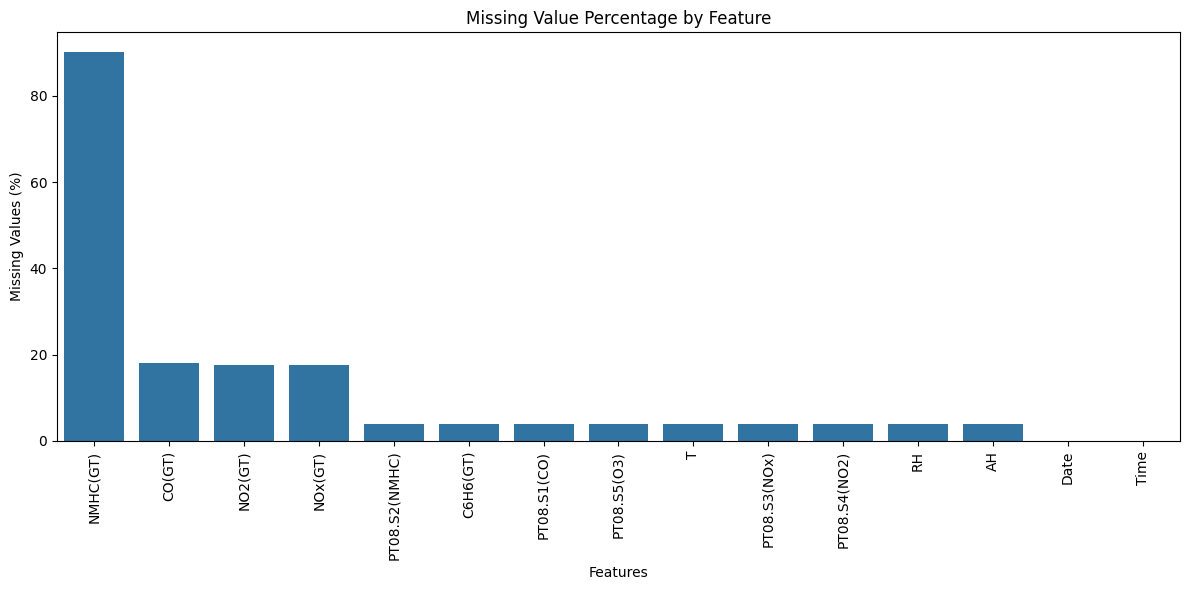

In [11]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_summary.index,
    y=missing_summary['Missing Percentage']
)

plt.xticks(rotation=90)
plt.ylabel("Missing Values (%)")
plt.xlabel("Features")
plt.title("Missing Value Percentage by Feature")

plt.tight_layout()
plt.show()

NMHC(GT) has the highest missing value. We will exclude it from the prediction input

Feature	Decision	Reason:

NMHC(GT) =	(Exclude)	Excessive missing values

CO(GT) = (Remove missing target rows)	Target must be known

NOx(GT), NO2(GT)	= (Exclude from inputs)	Avoid reference measurement dependency

Sensor measurements =	(Median imputation)	Preserve useful observations

T, RH, AH	= (Median imputation)	Preserve environmental information

In [12]:

# 1. Duplicate records
print("Duplicate records:",
      df_clean.duplicated().sum())

# 2. Convert Date and Time into datetime
df_clean['Time'] = (
    df_clean['Time'].astype(str)
    .str.replace('.', ':', regex=False)
)

df_clean['Datetime'] = pd.to_datetime(
    df_clean['Date'].astype(str) + ' ' +
    df_clean['Time'],
    dayfirst=True,
    errors='coerce'
)

print("\nFirst 10 datetime records:")
display(df_clean[['Date', 'Time', 'Datetime']].head(10))

print("Invalid datetime values:",
      df_clean['Datetime'].isna().sum())

# 3. Target availability
print("\nAvailable CO measurements:",
      df_clean['CO(GT)'].notna().sum())

print("Missing CO measurements:",
      df_clean['CO(GT)'].isna().sum())

# 4. Check completely missing sensor rows
sensor_columns = [
    'PT08.S1(CO)',
    'PT08.S2(NMHC)',
    'PT08.S3(NOx)',
    'PT08.S4(NO2)',
    'PT08.S5(O3)',
    'T', 'RH', 'AH'
]

all_sensor_missing = (
    df_clean[sensor_columns].isna().all(axis=1)
)

print("\nRows with all sensor readings missing:",
      all_sensor_missing.sum())


Duplicate records: 0

First 10 datetime records:


,Date,Time,Datetime
0,10/03/2004,18:00:00,2004-03-10 18:00:00
1,10/03/2004,19:00:00,2004-03-10 19:00:00
2,10/03/2004,20:00:00,2004-03-10 20:00:00
3,10/03/2004,21:00:00,2004-03-10 21:00:00
4,10/03/2004,22:00:00,2004-03-10 22:00:00
5,10/03/2004,23:00:00,2004-03-10 23:00:00
6,11/03/2004,00:00:00,2004-03-11 00:00:00
7,11/03/2004,01:00:00,2004-03-11 01:00:00
8,11/03/2004,02:00:00,2004-03-11 02:00:00
9,11/03/2004,03:00:00,2004-03-11 03:00:00


Invalid datetime values: 0

Available CO measurements: 7674
Missing CO measurements: 1683

Rows with all sensor readings missing: 366


# Preparing the modelling dataset

In [13]:
# 1. Define target and input features
target = "CO(GT)"

sensor_columns = [
    "PT08.S1(CO)",
    "PT08.S2(NMHC)",
    "PT08.S3(NOx)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "T",
    "RH",
    "AH"
]

# 2. Keep only the required columns
model_df = df_clean[["Datetime", target] + sensor_columns].copy()

# 3. Remove rows with missing target values
model_df = model_df.dropna(subset=[target])

# 4. Remove rows where every sensor feature is missing
model_df = model_df.dropna(subset=sensor_columns, how="all")

# 5. Sort chronologically
model_df = model_df.sort_values("Datetime").reset_index(drop=True)

# 6. Create time-based features
model_df["hour"] = model_df["Datetime"].dt.hour
model_df["day"] = model_df["Datetime"].dt.day
model_df["month"] = model_df["Datetime"].dt.month
model_df["weekday"] = model_df["Datetime"].dt.weekday

# 7. Display results
print("Final modelling dataset shape:", model_df.shape)
print("\nRemaining missing values:")
display(model_df.isnull().sum())

display(model_df.head())

display(model_df.tail())
print("Model dataset description")
model_df.describe()


Final modelling dataset shape: (7344, 14)

Remaining missing values:


,0
Datetime,0
CO(GT),0
PT08.S1(CO),0
PT08.S2(NMHC),0
PT08.S3(NOx),0
PT08.S4(NO2),0
PT08.S5(O3),0
T,0
RH,0
AH,0


,Datetime,CO(GT),PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,hour,day,month,weekday
0,2004-03-10 18:00:00,2.6,1360.0,1046.0,1056.0,1692.0,1268.0,13.6,48.9,0.7578,18,10,3,2
1,2004-03-10 19:00:00,2.0,1292.0,955.0,1174.0,1559.0,972.0,13.3,47.7,0.7255,19,10,3,2
2,2004-03-10 20:00:00,2.2,1402.0,939.0,1140.0,1555.0,1074.0,11.9,54.0,0.7502,20,10,3,2
3,2004-03-10 21:00:00,2.2,1376.0,948.0,1092.0,1584.0,1203.0,11.0,60.0,0.7867,21,10,3,2
4,2004-03-10 22:00:00,1.6,1272.0,836.0,1205.0,1490.0,1110.0,11.2,59.6,0.7888,22,10,3,2


,Datetime,CO(GT),PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,hour,day,month,weekday
7339,2005-04-04 10:00:00,3.1,1314.0,1101.0,539.0,1374.0,1729.0,21.9,29.3,0.7568,10,4,4,0
7340,2005-04-04 11:00:00,2.4,1163.0,1027.0,604.0,1264.0,1269.0,24.3,23.7,0.7119,11,4,4,0
7341,2005-04-04 12:00:00,2.4,1142.0,1063.0,603.0,1241.0,1092.0,26.9,18.3,0.6406,12,4,4,0
7342,2005-04-04 13:00:00,2.1,1003.0,961.0,702.0,1041.0,770.0,28.3,13.5,0.5139,13,4,4,0
7343,2005-04-04 14:00:00,2.2,1071.0,1047.0,654.0,1129.0,816.0,28.5,13.1,0.5028,14,4,4,0


Model dataset description


,Datetime,CO(GT),PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,hour,day,month,weekday
count,7344,7344.000000,7344.000000,7344.000000,7344.000000,7344.000000,7344.000000,7344.000000,7344.000000,7344.000000,7344.000000,7344.000000,7344.000000,7344.000000
mean,2004-09-27 03:18:15.098039168,2.129711,1110.580746,947.198121,826.920071,1444.752723,1043.512936,17.770425,49.060076,0.989453,11.699619,15.815087,6.086193,3.043437
min,2004-03-10 18:00:00,0.100000,647.000000,387.000000,322.000000,551.000000,221.000000,-1.900000,9.200000,0.184700,0.000000,1.000000,1.000000,0.000000
25%,2004-06-15 18:45:00,1.100000,946.000000,743.000000,649.000000,1203.000000,744.750000,11.200000,35.400000,0.698100,6.000000,8.000000,3.000000,1.000000
50%,2004-09-29 08:30:00,1.800000,1075.000000,919.000000,795.000000,1447.000000,990.000000,16.900000,49.300000,0.959700,12.000000,16.000000,6.000000,3.000000
75%,2005-01-10 16:15:00,2.800000,1246.000000,1125.250000,960.000000,1673.000000,1305.000000,23.800000,62.500000,1.258600,18.000000,23.000000,9.000000,5.000000
max,2005-04-04 14:00:00,11.900000,2040.000000,2214.000000,2683.000000,2775.000000,2523.000000,44.600000,88.700000,2.180600,23.000000,31.000000,12.000000,6.000000
std,NaN,1.436472,218.681331,265.471608,256.648430,350.344170,405.569613,8.862688,17.451563,0.399889,6.907054,8.736795,3.485353,2.021643


# Check the target and chronological coverage

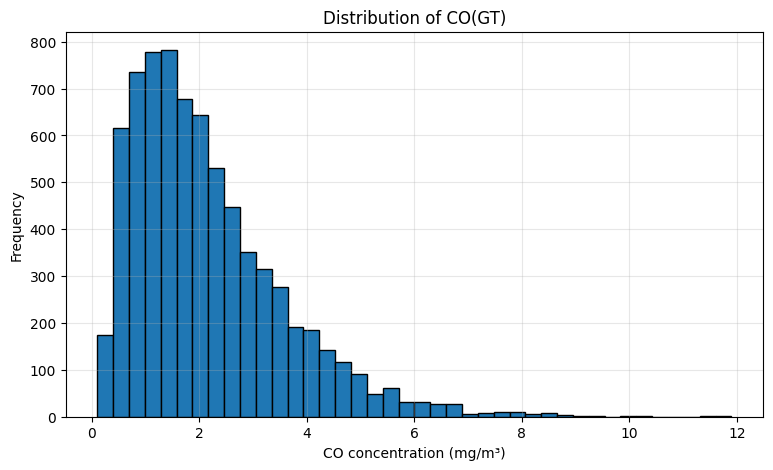

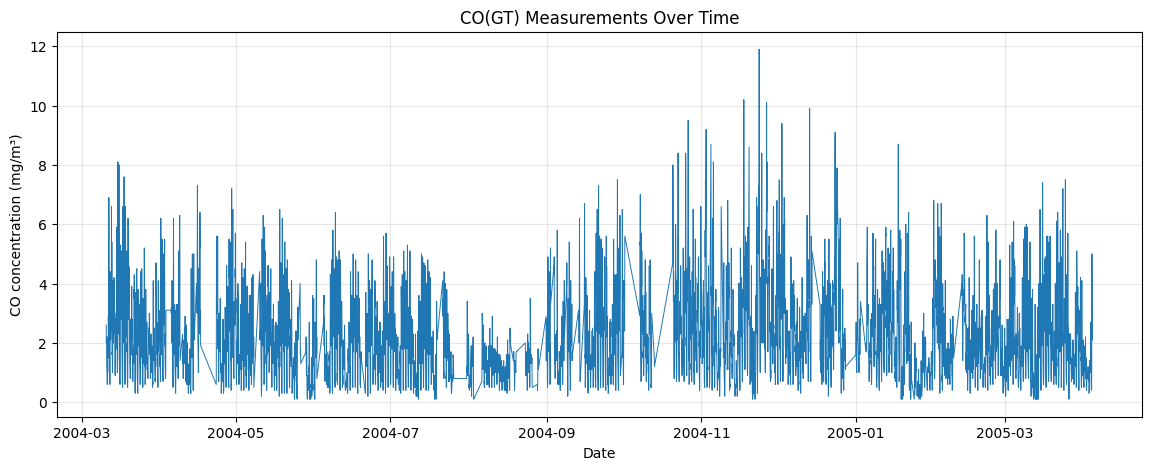

Start date: 2004-03-10 18:00:00
End date: 2005-04-04 14:00:00
Total usable records: 7344
Remaining missing sensor values: 0


In [14]:

import matplotlib.pyplot as plt

# CO target distribution
plt.figure(figsize=(9, 5))
plt.hist(model_df[target], bins=40, edgecolor="black")
plt.title("Distribution of CO(GT)")
plt.xlabel("CO concentration (mg/m³)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.show()

# CO measurements over time
plt.figure(figsize=(14, 5))
plt.plot(model_df["Datetime"], model_df[target], linewidth=0.7)
plt.title("CO(GT) Measurements Over Time")
plt.xlabel("Date")
plt.ylabel("CO concentration (mg/m³)")
plt.grid(alpha=0.3)
plt.show()

# Chronological coverage
print("Start date:", model_df["Datetime"].min())
print("End date:", model_df["Datetime"].max())
print("Total usable records:", len(model_df))
print("Remaining missing sensor values:",
      model_df[sensor_columns].isnull().sum().sum())


# Setion 3: Exploratory Data Analysis (EDA)

Descriptive statistics

In [15]:
#statistical overview

display(model_df.drop(columns =["Datetime"]).describe().round(2))

print("CO(GT) Statistics")
print("Mean", round(model_df[target].mean(), 2))
print("Median", round(model_df[target].median(), 2))
print("Min", round(model_df[target].min()))
print("Max", round(model_df[target].max()))
print("Standard deviation:", round(model_df[target].std(), 2))


,CO(GT),PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,hour,day,month,weekday
count,7344.00,7344.00,7344.00,7344.00,7344.00,7344.00,7344.00,7344.00,7344.00,7344.00,7344.00,7344.00,7344.00
mean,2.13,1110.58,947.20,826.92,1444.75,1043.51,17.77,49.06,0.99,11.70,15.82,6.09,3.04
std,1.44,218.68,265.47,256.65,350.34,405.57,8.86,17.45,0.40,6.91,8.74,3.49,2.02
min,0.10,647.00,387.00,322.00,551.00,221.00,-1.90,9.20,0.18,0.00,1.00,1.00,0.00
25%,1.10,946.00,743.00,649.00,1203.00,744.75,11.20,35.40,0.70,6.00,8.00,3.00,1.00
50%,1.80,1075.00,919.00,795.00,1447.00,990.00,16.90,49.30,0.96,12.00,16.00,6.00,3.00
75%,2.80,1246.00,1125.25,960.00,1673.00,1305.00,23.80,62.50,1.26,18.00,23.00,9.00,5.00
max,11.90,2040.00,2214.00,2683.00,2775.00,2523.00,44.60,88.70,2.18,23.00,31.00,12.00,6.00


CO(GT) Statistics
Mean 2.13
Median 1.8
Min 0
Max 12
Standard deviation: 1.44


Correlation

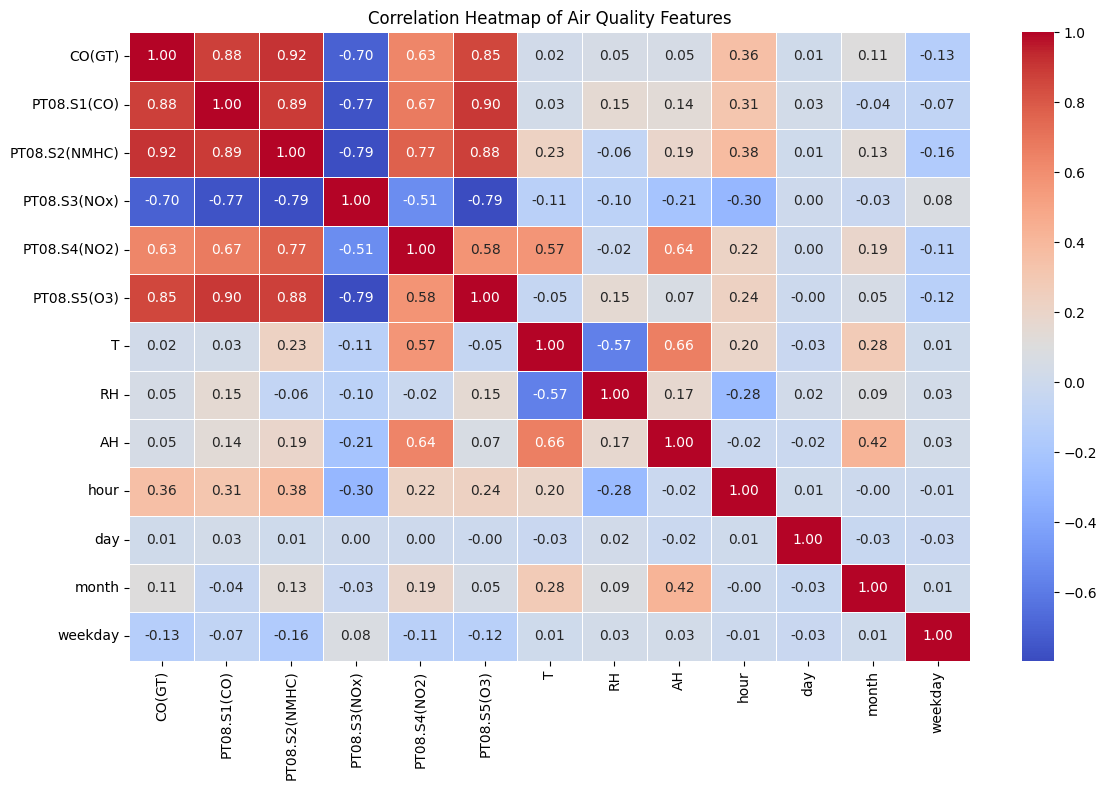

Correlation with CO(GT):


,Correlation
PT08.S2(NMHC),0.916
PT08.S1(CO),0.879
PT08.S5(O3),0.854
PT08.S4(NO2),0.631
hour,0.360
month,0.105
RH,0.049
AH,0.049
T,0.022
day,0.014


In [16]:
# Calculate correlation matrix
correlation_matrix = model_df.drop(columns=["Datetime"]).corr()

# Visualize correlations
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Air Quality Features")
plt.tight_layout()
plt.show()

# Correlation with target
target_correlation = correlation_matrix["CO(GT)"].drop("CO(GT)")
target_correlation = target_correlation.sort_values(ascending=False)

print("Correlation with CO(GT):")
display(target_correlation.to_frame("Correlation").round(3))


CO variation throughout the day

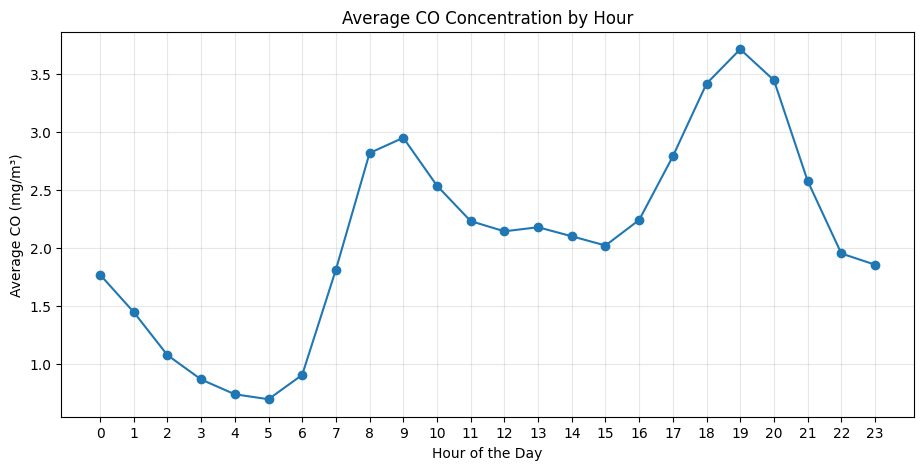

In [17]:
hourly_co = model_df.groupby("hour")["CO(GT)"].mean()

plt.figure(figsize=(11, 5))
plt.plot(hourly_co.index, hourly_co.values, marker="o")
plt.title("Average CO Concentration by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average CO (mg/m³)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.show()


Morning: approximately 8–10 AM.



Evening: approximately 5–8 PM, with the highest average around 7 PM.


The lowest average concentration appears around 4–5 AM.

CO variation across months

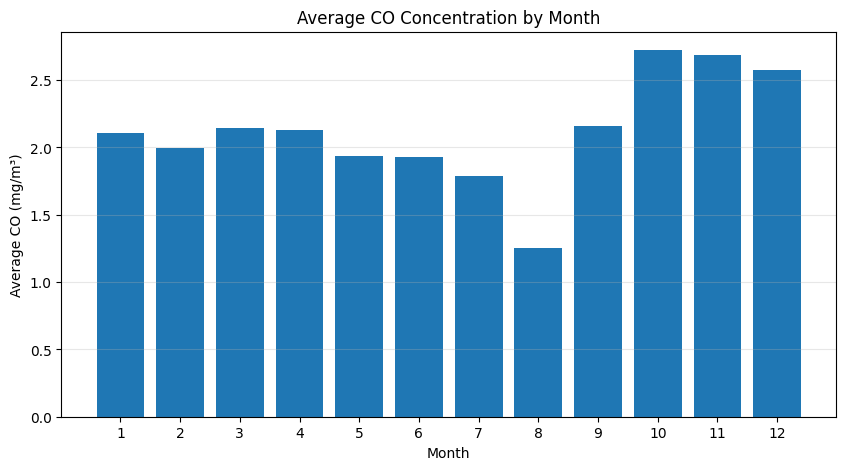

In [18]:
monthly_co = model_df.groupby("month")["CO(GT)"].mean()

plt.figure(figsize=(10, 5))
plt.bar(monthly_co.index, monthly_co.values)
plt.title("Average CO Concentration by Month")
plt.xlabel("Month")
plt.ylabel("Average CO (mg/m³)")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.show()


August have lowest

October, November, December have highest average


Relationship between sensor readings and CO

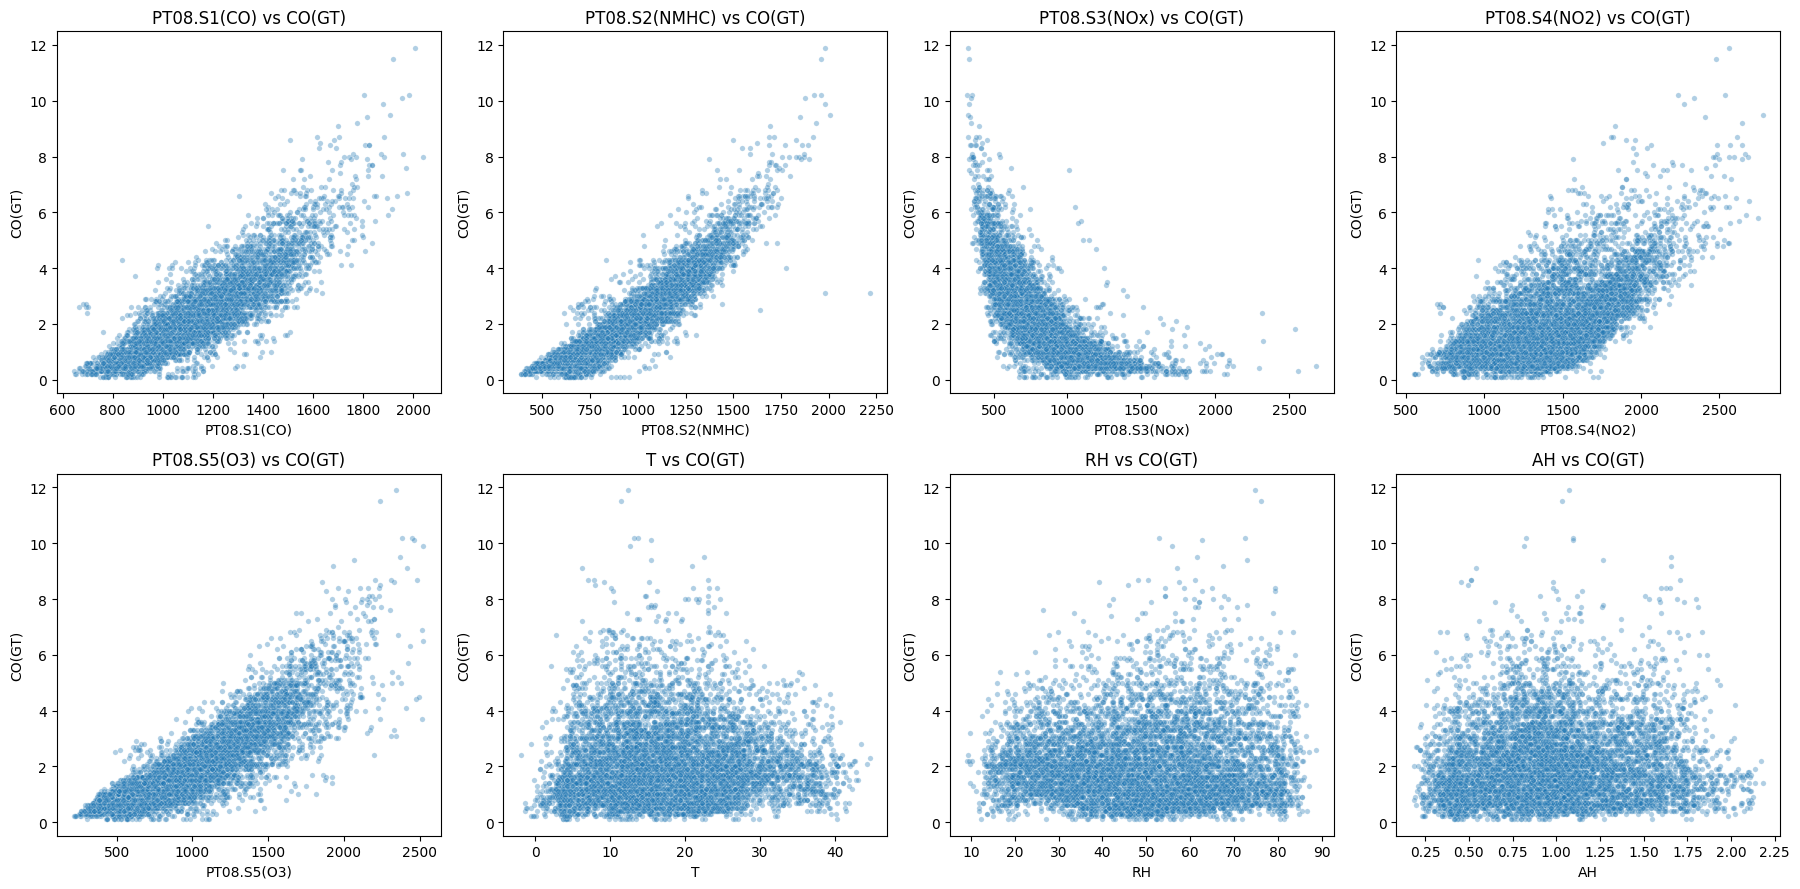

In [19]:
selected_features = [
    "PT08.S1(CO)",
    "PT08.S2(NMHC)",
    "PT08.S3(NOx)",
    "PT08.S4(NO2)",
    "PT08.S5(O3)",
    "T",
    "RH",
    "AH"
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, feature in enumerate(selected_features):
    sns.scatterplot(
        data=model_df,
        x=feature,
        y="CO(GT)",
        alpha=0.35,
        s=15,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} vs CO(GT)")

plt.tight_layout()
plt.show()


**Interpretation:**

PT08.S1(CO): clear positive relationship.



PT08.S2(NMHC): particularly strong positive pattern.



PT08.S3(NOx): clear negative pattern.



PT08.S4(NO2) : positive relationships.


PT08.S5(O3): positive relationships.



T, RH, and AH: more dispersed relationships with CO.

# Section 4: Feature engineering and chronological splitting

In [20]:
# cylclical feature

final_df = model_df.copy()

#cyclical encoding for hour (24 hr)
final_df["hour_sin"] = np.sin(2 * np.pi * final_df["hour"] / 24)
final_df["hour_cos"] = np.cos(2 * np.pi * final_df["hour"] / 24)

#cyclical encoding for month (12 month)
final_df["month_sin"] = np.sin(2 * np.pi * (final_df["month"]-1 )/ 12)
final_df["month_cos"] = np.cos(2 * np.pi * (final_df["month"]-1) / 12)

#cyclical encoding for weekdays (7 days)
final_df["weekday_sin"] = np.sin(2 * np.pi * final_df["weekday"] / 7)
final_df["weekday_cos"] = np.cos(2 * np.pi * final_df["weekday"] / 7)

print("Done")
final_df

Done


,Datetime,CO(GT),PT08.S1(CO),PT08.S2(NMHC),PT08.S3(NOx),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,hour,day,month,weekday,hour_sin,hour_cos,month_sin,month_cos,weekday_sin,weekday_cos
0,2004-03-10 18:00:00,2.6,1360.0,1046.0,1056.0,1692.0,1268.0,13.6,48.9,0.7578,18,10,3,2,-1.000000e+00,-1.836970e-16,0.866025,5.000000e-01,0.974928,-0.222521
1,2004-03-10 19:00:00,2.0,1292.0,955.0,1174.0,1559.0,972.0,13.3,47.7,0.7255,19,10,3,2,-9.659258e-01,2.588190e-01,0.866025,5.000000e-01,0.974928,-0.222521
2,2004-03-10 20:00:00,2.2,1402.0,939.0,1140.0,1555.0,1074.0,11.9,54.0,0.7502,20,10,3,2,-8.660254e-01,5.000000e-01,0.866025,5.000000e-01,0.974928,-0.222521
3,2004-03-10 21:00:00,2.2,1376.0,948.0,1092.0,1584.0,1203.0,11.0,60.0,0.7867,21,10,3,2,-7.071068e-01,7.071068e-01,0.866025,5.000000e-01,0.974928,-0.222521
4,2004-03-10 22:00:00,1.6,1272.0,836.0,1205.0,1490.0,1110.0,11.2,59.6,0.7888,22,10,3,2,-5.000000e-01,8.660254e-01,0.866025,5.000000e-01,0.974928,-0.222521
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7339,2005-04-04 10:00:00,3.1,1314.0,1101.0,539.0,1374.0,1729.0,21.9,29.3,0.7568,10,4,4,0,5.000000e-01,-8.660254e-01,1.000000,6.123234e-17,0.000000,1.000000
7340,2005-04-04 11:00:00,2.4,1163.0,1027.0,604.0,1264.0,1269.0,24.3,23.7,0.7119,11,4,4,0,2.588190e-01,-9.659258e-01,1.000000,6.123234e-17,0.000000,1.000000
7341,2005-04-04 12:00:00,2.4,1142.0,1063.0,603.0,1241.0,1092.0,26.9,18.3,0.6406,12,4,4,0,1.224647e-16,-1.000000e+00,1.000000,6.123234e-17,0.000000,1.000000
7342,2005-04-04 13:00:00,2.1,1003.0,961.0,702.0,1041.0,770.0,28.3,13.5,0.5139,13,4,4,0,-2.588190e-01,-9.659258e-01,1.000000,6.123234e-17,0.000000,1.000000


Preparing X and y

In [21]:

feature_columns = sensor_columns + [
    "hour_sin",
    "hour_cos",
    "month_sin",
    "month_cos",
    "weekday_sin",
    "weekday_cos"
]

X = final_df[feature_columns]
y = final_df["CO(GT)"]

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nSelected features:")
print(feature_columns)


Input feature shape: (7344, 14)
Target shape: (7344,)

Selected features:
['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'weekday_sin', 'weekday_cos']


train/test split

In [22]:

# Chronological 80:20 split
split_index = int(len(final_df) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining period:")
print(final_df["Datetime"].iloc[0])
print("to")
print(final_df["Datetime"].iloc[split_index - 1])

print("\nTesting period:")
print(final_df["Datetime"].iloc[split_index])
print("to")
print(final_df["Datetime"].iloc[-1])


Training records: 5875
Testing records: 1469

Training period:
2004-03-10 18:00:00
to
2005-01-28 11:00:00

Testing period:
2005-01-28 12:00:00
to
2005-04-04 14:00:00


# Model training (Regression)

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
# Evaluation function
def evaluate_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    results = {
        "Train MAE": mean_absolute_error(y_train, train_predictions),
        "Test MAE": mean_absolute_error(y_test, test_predictions),
        "Test MSE": mean_squared_error(y_test, test_predictions),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_predictions)),
        "Test R2": r2_score(y_test, test_predictions)
    }

    return results

**Three models**

In [24]:

# Model 1: Dummy Regressor (baseline)
dummy_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DummyRegressor(strategy="mean"))
])

# Model 2: Linear Regression
linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# Model 3: Random Forest Regressor
random_forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

print("All three models are ready.")


All three models are ready.


In [25]:

models = {
    "Dummy Regressor": dummy_model,
    "Linear Regression": linear_model,
    "Random Forest": random_forest_model
}

results = []

for model_name, model in models.items():
    print(f"Training {model_name}...")

    model_results = evaluate_model(
        model,
        X_train,
        y_train,
        X_test,
        y_test
    )

    model_results["Model"] = model_name
    results.append(model_results)

results_df = pd.DataFrame(results)

results_df = results_df[
    ["Model", "Train MAE", "Test MAE", "Test MSE", "Test RMSE", "Test R2"]
]

display(results_df.round(4))


Training Dummy Regressor...
Training Linear Regression...
Training Random Forest...


,Model,Train MAE,Test MAE,Test MSE,Test RMSE,Test R2
0,Dummy Regressor,1.1276,1.0677,1.7416,1.3197,-0.0299
1,Linear Regression,0.3086,0.6254,0.5493,0.7411,0.6752
2,Random Forest,0.0830,0.3292,0.2393,0.4892,0.8585


* Dummy regressor performs worse

* Linear Regression performs moderate

* Random forest performs well approxiamtely 85.35% of the variation in the test target

Random forest may be overfitting as the training error is much lower than testing error.




# Random Forest hyperparameter tuning

We'll use **RandomizedSearchCV** with **TimeSeriesSplit** and **optimize MAE**

In [26]:

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

# Five chronological validation folds
tscv = TimeSeriesSplit(n_splits=5)

print("Number of validation folds:", tscv.get_n_splits(X_train))

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), 1):
    print(
        f"Fold {fold}: "
        f"Training = {len(train_idx)}, "
        f"Validation = {len(val_idx)}"
    )


Number of validation folds: 5
Fold 1: Training = 980, Validation = 979
Fold 2: Training = 1959, Validation = 979
Fold 3: Training = 2938, Validation = 979
Fold 4: Training = 3917, Validation = 979
Fold 5: Training = 4896, Validation = 979


We'll investigate:
- n_estimators: number of decision trees.
- max_depth: maximum tree depth.
- min_samples_split: minimum samples required to split a node.
- min_samples_leaf: minimum samples allowed in a leaf.
- max_features: number or proportion of features considered at each split.

In [27]:
# Random Forest pipeline
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

# Hyperparameter search space
param_distributions = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4, 6],
    "model__max_features": [0.7, 1.0]
}

# Randomized search
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit using training data only
random_search.fit(X_train, y_train)

print("Best parameters:")
print(random_search.best_params_)

print("\nBest cross-validation MAE:")
print(-random_search.best_score_)


Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_features': 0.7, 'model__max_depth': 20}

Best cross-validation MAE:
0.3212576127723903


Evaluate the tuned model

In [ ]:
# Retrieve the best model
best_rf_model = random_search.best_estimator_

# Predictions
train_predictions = best_rf_model.predict(X_train)
test_predictions = best_rf_model.predict(X_test)

# Evaluation
tuned_results = {
    "Model": "Tuned Random Forest",
    "Train MAE": mean_absolute_error(y_train, train_predictions),
    "Test MAE": mean_absolute_error(y_test, test_predictions),
    "Test MSE": mean_squared_error(y_test, test_predictions),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, test_predictions)),
    "Test R2": r2_score(y_test, test_predictions)
}

tuned_results_df = pd.DataFrame([tuned_results])

display(tuned_results_df.round(4))


,Model,Train MAE,Test MAE,Test MSE,Test RMSE,Test R2
0,Tuned Random Forest,0.1044,0.3149,0.2177,0.4666,0.8713


Compare original and tuned Random Forest

In [ ]:
comparison = pd.DataFrame([
    {
        "Model": "Original Random Forest",
        "Test MAE": 0.3292,
        "Test RMSE": 0.4892,
        "Test R2": 0.8585
    },
    {
        "Model": "Tuned Random Forest",
        "Test MAE": tuned_results["Test MAE"],
        "Test RMSE": tuned_results["Test RMSE"],
        "Test R2": tuned_results["Test R2"]
    }
])

display(comparison.round(4))


,Model,Test MAE,Test RMSE,Test R2
0,Original Random Forest,0.3292,0.4892,0.8585
1,Tuned Random Forest,0.3149,0.4666,0.8713


**Actual vs. predicted values**

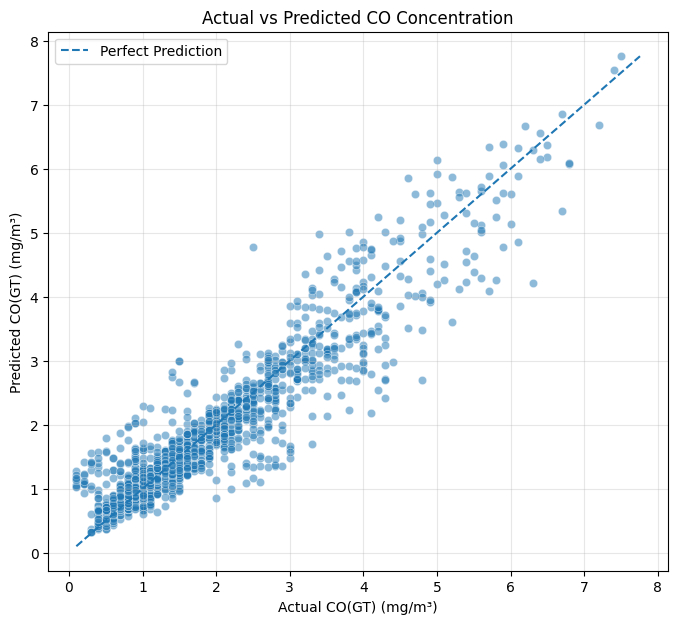

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Actual vs predicted
plt.figure(figsize=(8, 7))

sns.scatterplot(
    x=y_test,
    y=test_predictions,
    alpha=0.5
)

# Perfect prediction reference line
min_value = min(y_test.min(), test_predictions.min())
max_value = max(y_test.max(), test_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual CO(GT) (mg/m³)")
plt.ylabel("Predicted CO(GT) (mg/m³)")
plt.title("Actual vs Predicted CO Concentration")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Prediction over time**

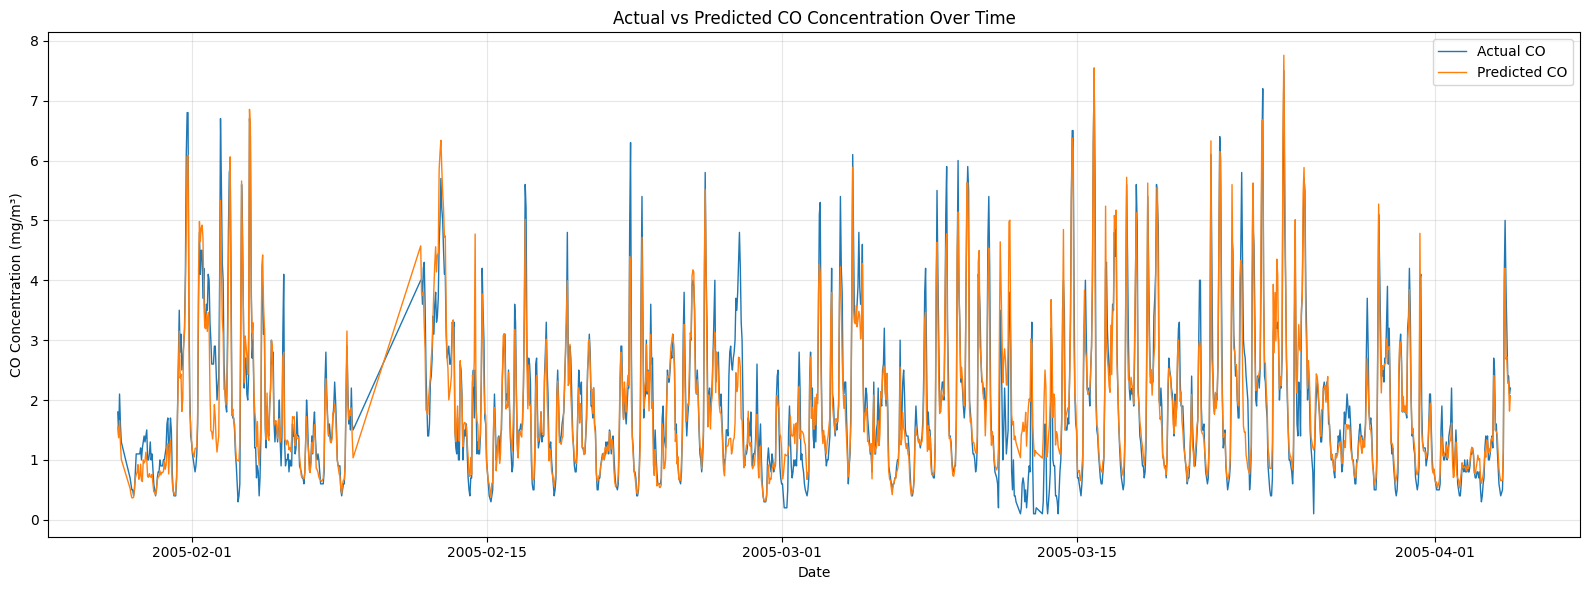

In [ ]:

prediction_results = pd.DataFrame({
    "Datetime": final_df["Datetime"].iloc[split_index:].values,
    "Actual": y_test.values,
    "Predicted": test_predictions
})

plt.figure(figsize=(16, 6))

plt.plot(
    prediction_results["Datetime"],
    prediction_results["Actual"],
    label="Actual CO",
    linewidth=1
)

plt.plot(
    prediction_results["Datetime"],
    prediction_results["Predicted"],
    label="Predicted CO",
    linewidth=1
)

plt.title("Actual vs Predicted CO Concentration Over Time")
plt.xlabel("Date")
plt.ylabel("CO Concentration (mg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Feature importance

,Feature,Importance
1,PT08.S2(NMHC),0.6394
4,PT08.S5(O3),0.1459
0,PT08.S1(CO),0.1196
2,PT08.S3(NOx),0.0247
5,T,0.0159
11,month_cos,0.0097
3,PT08.S4(NO2),0.0093
7,AH,0.0082
8,hour_sin,0.0077
6,RH,0.0066


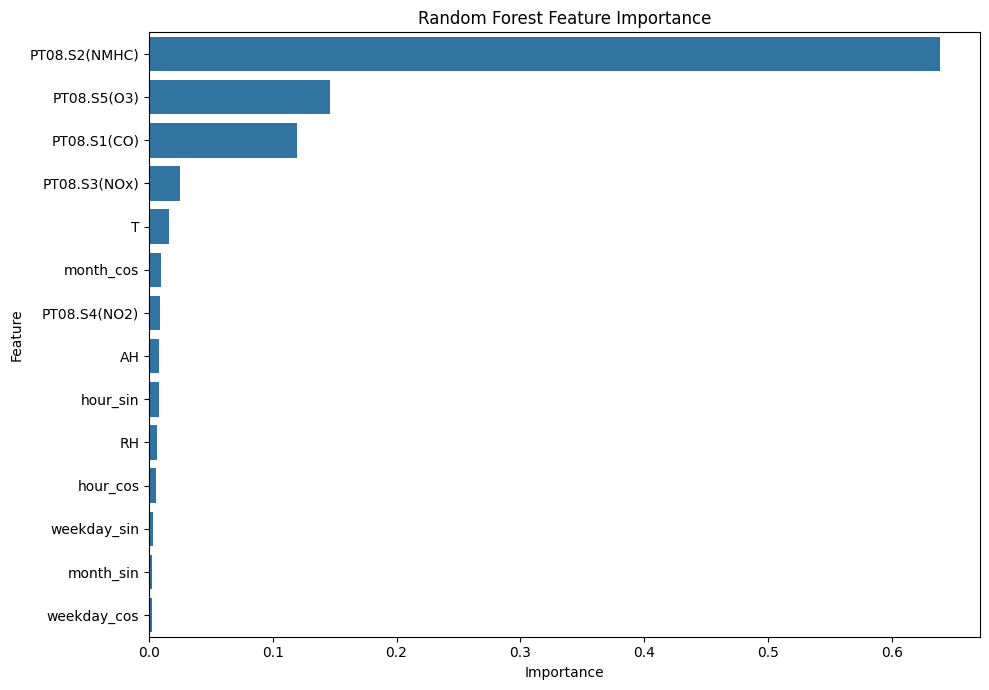

In [ ]:

# Extract trained Random Forest
rf_estimator = best_rf_model.named_steps["model"]

# Feature importance
importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_estimator.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.round(4))

# Plot feature importance
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


# Section 5: Feature ablation experiment

We'll compare two versions of the model:
- Model A — Sensor and environmental features: 8 original measurements.
- Model B — Sensor, environmental, and time features: all 14 features.

In [ ]:

from sklearn.base import clone

# Model A: Original sensor and environmental features
sensor_feature_columns = sensor_columns

# Model B: Sensor + engineered time features
all_feature_columns = feature_columns

# Prepare datasets using the same chronological split
X_train_sensor = X_train[sensor_feature_columns]
X_test_sensor = X_test[sensor_feature_columns]

X_train_full = X_train[all_feature_columns]
X_test_full = X_test[all_feature_columns]

# Model A: Train without engineered time features
sensor_only_model = clone(best_rf_model)

sensor_only_model.fit(X_train_sensor, y_train)

sensor_predictions = sensor_only_model.predict(X_test_sensor)

# Model B: Train with all features
full_feature_model = clone(best_rf_model)

full_feature_model.fit(X_train_full, y_train)

full_predictions = full_feature_model.predict(X_test_full)

# Compare performance
ablation_results = pd.DataFrame([
    {
        "Feature Set": "Sensor + Environmental",
        "Features": len(sensor_feature_columns),
        "MAE": mean_absolute_error(y_test, sensor_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, sensor_predictions)),
        "R2": r2_score(y_test, sensor_predictions)
    },
    {
        "Feature Set": "Sensor + Environmental + Time",
        "Features": len(all_feature_columns),
        "MAE": mean_absolute_error(y_test, full_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, full_predictions)),
        "R2": r2_score(y_test, full_predictions)
    }
])

display(ablation_results.round(4))


,Feature Set,Features,MAE,RMSE,R2
0,Sensor + Environmental,8,0.3428,0.5000,0.8521
1,Sensor + Environmental + Time,14,0.3149,0.4666,0.8713


**Residual analysis**

Residual Analysis
-----------------------------------
Mean: 0.0292
Median: 0.0043
Standard deviation: 0.4657
Minimum: -2.2722
Maximum: 2.0965


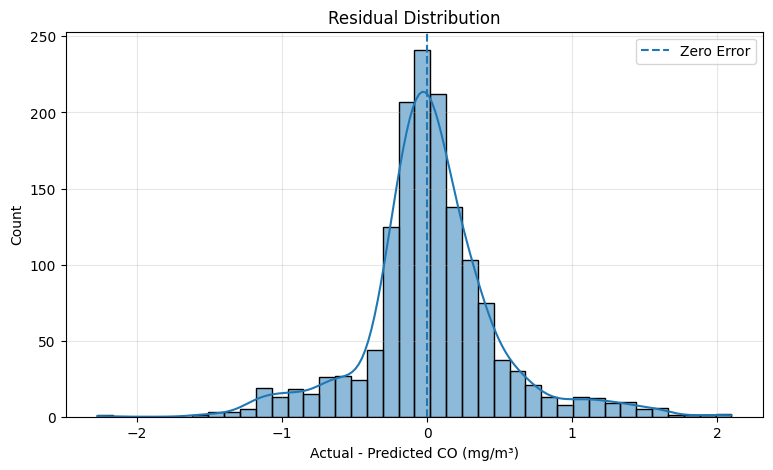

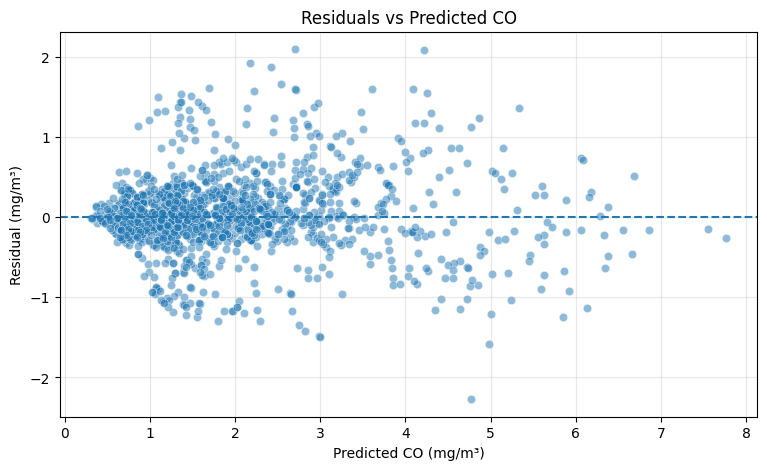

In [ ]:

# Calculate residuals
residuals = y_test.values - test_predictions

# Residual statistics
print("Residual Analysis")
print("-" * 35)
print("Mean:", round(np.mean(residuals), 4))
print("Median:", round(np.median(residuals), 4))
print("Standard deviation:", round(np.std(residuals), 4))
print("Minimum:", round(np.min(residuals), 4))
print("Maximum:", round(np.max(residuals), 4))

# Residual distribution
plt.figure(figsize=(9, 5))
sns.histplot(residuals, bins=40, kde=True)
plt.axvline(0, linestyle="--", label="Zero Error")
plt.title("Residual Distribution")
plt.xlabel("Actual - Predicted CO (mg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Residuals vs predicted values
plt.figure(figsize=(9, 5))
sns.scatterplot(
    x=test_predictions,
    y=residuals,
    alpha=0.5
)
plt.axhline(0, linestyle="--")
plt.title("Residuals vs Predicted CO")
plt.xlabel("Predicted CO (mg/m³)")
plt.ylabel("Residual (mg/m³)")
plt.grid(alpha=0.3)
plt.show()


**residual statistics and residual-versus-predicted plot.**

Mean residual: 0.0292
Median residual: 0.0043
Standard deviation: 0.4657
Minimum residual: -2.2722
Maximum residual: 2.0965


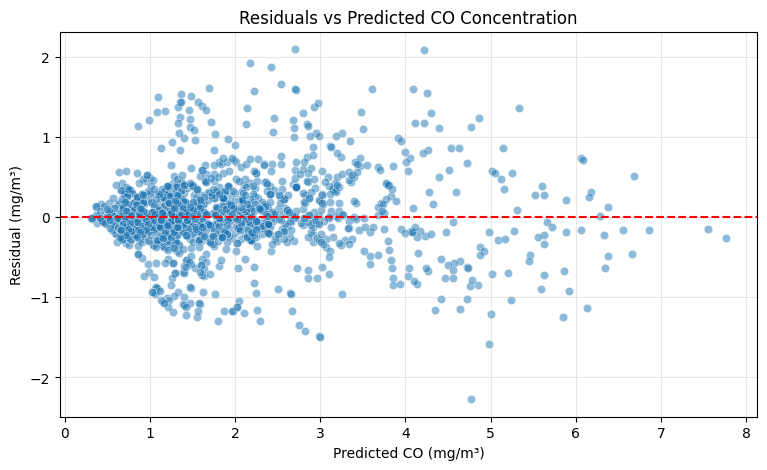

In [ ]:

# Residual statistics
print("Mean residual:", round(np.mean(residuals), 4))
print("Median residual:", round(np.median(residuals), 4))
print("Standard deviation:", round(np.std(residuals), 4))
print("Minimum residual:", round(np.min(residuals), 4))
print("Maximum residual:", round(np.max(residuals), 4))

# Residuals vs predicted values
plt.figure(figsize=(9, 5))

sns.scatterplot(
    x=test_predictions,
    y=residuals,
    alpha=0.5
)

plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals vs Predicted CO Concentration")
plt.xlabel("Predicted CO (mg/m³)")
plt.ylabel("Residual (mg/m³)")
plt.grid(alpha=0.3)
plt.show()


# Model stability analysis

In [ ]:

from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.base import clone
import pandas as pd
import numpy as np

# Five chronological folds
stability_cv = TimeSeriesSplit(n_splits=5)

# Clone the tuned model
stability_model = clone(best_rf_model)

# Cross-validation
cv_results = cross_validate(
    estimator=stability_model,
    X=X_train,
    y=y_train,
    cv=stability_cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    return_train_score=True,
    n_jobs=-1
)

# Prepare results
stability_df = pd.DataFrame({
    "Fold": range(1, 6),
    "Train MAE": -cv_results["train_mae"],
    "Validation MAE": -cv_results["test_mae"],
    "Validation RMSE": -cv_results["test_rmse"],
    "Validation R2": cv_results["test_r2"]
})

display(stability_df.round(4))


,Fold,Train MAE,Validation MAE,Validation RMSE,Validation R2
0,1,0.0829,0.3031,0.3887,0.8942
1,2,0.0883,0.1995,0.2798,0.9275
2,3,0.0845,0.2292,0.3296,0.9456
3,4,0.0818,0.3917,0.6171,0.8920
4,5,0.0909,0.4828,0.7223,0.7738


**average performance**

In [ ]:

stability_summary = stability_df.drop(
    columns=["Fold"]
).agg(["mean", "std"]).T

stability_summary.columns = [
    "Mean",
    "Standard Deviation"
]

display(stability_summary.round(4))


,Mean,Standard Deviation
Train MAE,0.0857,0.0038
Validation MAE,0.3213,0.1169
Validation RMSE,0.4675,0.1922
Validation R2,0.8866,0.0670


Visualize validation performance

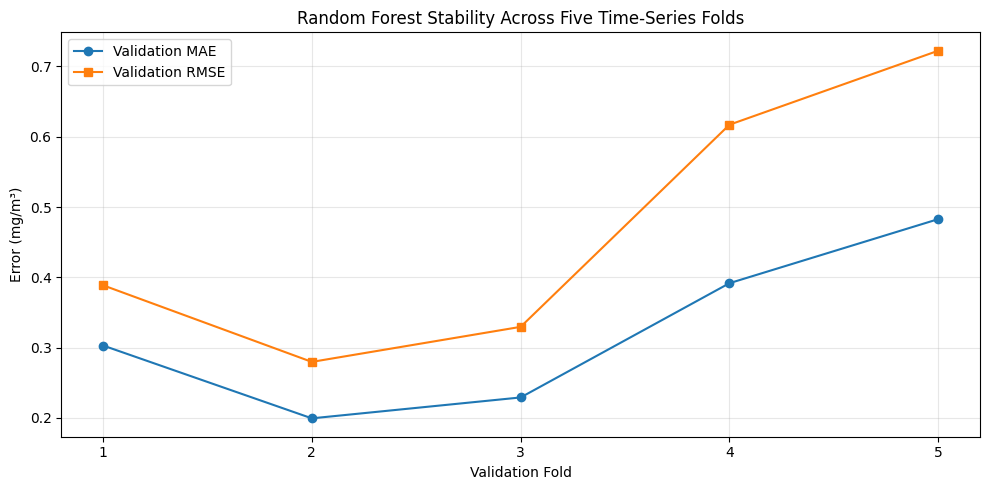

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    stability_df["Fold"],
    stability_df["Validation MAE"],
    marker="o",
    label="Validation MAE"
)

plt.plot(
    stability_df["Fold"],
    stability_df["Validation RMSE"],
    marker="s",
    label="Validation RMSE"
)

plt.title("Random Forest Stability Across Five Time-Series Folds")
plt.xlabel("Validation Fold")
plt.ylabel("Error (mg/m³)")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Saving the final evaluated model

In [ ]:

import os
import joblib
import json

# Create model directory
os.makedirs("models", exist_ok=True)

# Save the complete pipeline
model_path = "models/best_model_pipeline.joblib"

joblib.dump(best_rf_model, model_path)

# Save model information
model_metadata = {
    "model_name": "Tuned_Random_Forest_Regressor_SDG",
    "target": "CO(GT)",
    "target_unit": "mg/m3",
    "features": list(feature_columns),
    "number_of_features": len(feature_columns),
    "test_metrics": {
        "MAE": 0.3149,
        "RMSE": 0.4666,
        "R2": 0.8713
    },
    "cross_validation": {
        "folds": 5,
        "mean_MAE": 0.3213,
        "mean_RMSE": 0.4675,
        "mean_R2": 0.8866
    }
}

with open("models/model_metadata.json", "w") as file:
    json.dump(model_metadata, file, indent=4)

print("Model saved successfully!")
print("Location:", model_path)


Model saved successfully!
Location: models/best_model_pipeline.joblib


Model testing

In [ ]:

# Load saved pipeline
loaded_model = joblib.load(
    "models/best_model_pipeline.joblib"
)

# Generate predictions
loaded_predictions = loaded_model.predict(X_test)

# Compare with previous predictions
print("Predictions identical:",np.allclose(test_predictions, loaded_predictions))

print("Loaded model MAE:",round(mean_absolute_error(y_test, loaded_predictions), 4))

print("Loaded model RMSE:",round(np.sqrt(mean_squared_error(y_test, loaded_predictions)), 4))

print("Loaded model R2:",round(r2_score(y_test, loaded_predictions), 4))


Predictions identical: True
Loaded model MAE: 0.3149
Loaded model RMSE: 0.4666
Loaded model R2: 0.8713


In [ ]:
import sklearn
print(sklearn.__version__)

1.6.1
